# 13 E_peak against MVT: merge and Dichiara Fig. 2

Joins my E_peak table (`shared/epeak_230307A.csv`, notebook 12) to MVT values by window label, reproduces
Dichiara's Fig. 2 (MVT and E_peak against time) and makes the first E_peak vs MVT plot.

MVT values: from `shared/mvt_230307A.csv` once that file exists. Until then the notebook uses the MVT
published by Dichiara (Table 1, 8-1000 keV), so that the merge and the plots are tested and the figure can be
compared with theirs. The MVT source is printed and written on every figure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from settings import (DATA_DIR, BURST_ID, FIGURE_DIR, WINDOWS_FILE, BAD_TIME_INTERVAL, SOFT_DETECTORS,
                      load_windows)
from lightcurve_tools import aligned_bin_edges, band_counts

SHARED = WINDOWS_FILE.parent
epeak = pd.read_csv(SHARED / "epeak_230307A.csv").set_index("label")
windows = load_windows()

mvt_file = SHARED / "mvt_230307A.csv"
if mvt_file.exists():
    mvt = pd.read_csv(mvt_file).set_index("label")
    mvt_source = "mvt_230307A.csv"
else:
    # Dichiara et al. (2023) Table 1, 8-1000 keV; the 0.32-3 s value is an upper limit
    mvt = pd.DataFrame({"mvt_s": [0.017, 0.012, 0.015, 0.062], "mvt_err_lo_s": [0.002, np.nan, 0.002, 0.004],
                        "mvt_err_hi_s": [0.002, np.nan, 0.002, 0.004], "band_keV": "8-1000",
                        "upper_limit": [False, True, False, False]},
                       index=pd.Index(["pre", "m01", "t1_07_18", "t1_18_40"], name="label"))
    mvt_source = "Dichiara et al. (2023) Table 1"
print("MVT from:", mvt_source)

MVT from: Dichiara et al. (2023) Table 1


## Merge

An inner join on the label. Every MVT window has to be in the E_peak table and appear once; any window
without a match is listed rather than silently dropped.

In [2]:
assert epeak.index.is_unique and mvt.index.is_unique
missing = sorted(set(mvt.index) - set(epeak.index))
print("MVT windows with no E_peak:", missing or "none")
print("E_peak windows with no MVT:", sorted(set(epeak.index) - set(mvt.index)))
merged = epeak.join(mvt, how="inner")
for label, row in merged.iterrows():
    assert np.allclose([row.t_start, row.t_stop], windows.loc[label, ["t_start", "t_stop"]])
merged["Epeak_err"] = np.hypot(0.5 * (merged.Epeak_err_lo + merged.Epeak_err_hi), merged.Epeak_sys)
instrument = pd.read_csv(SHARED / "epeak_230307A_instrument_check.csv").set_index("label")     # notebook 15
merged["Epeak_instrument_keV"] = merged.Epeak_keV * instrument.Epeak_instrument_frac
merged[["t_start", "t_stop", "Epeak_keV", "Epeak_err", "Epeak_instrument_keV", "Epeak_rest_keV", "mvt_s", "mvt_err_lo_s",
        "upper_limit"]].round(4)

MVT windows with no E_peak: none
E_peak windows with no MVT: ['m02', 'm03', 'm04', 'm05', 'm06', 'm07', 'm08', 'm09', 'm10', 'm11']


,t_start,t_stop,Epeak_keV,Epeak_err,Epeak_instrument_keV,Epeak_rest_keV,mvt_s,mvt_err_lo_s,upper_limit
label,,,,,,,,,
pre,-0.064,0.32,170.300,7.2157,34.0600,181.369,0.017,0.002,False
m01,0.320,3.00,914.041,6.6643,91.4041,973.453,0.012,NaN,True
t1_07_18,7.000,18.00,878.369,4.3224,87.8369,935.463,0.015,0.002,False
t1_18_40,18.000,40.00,450.296,6.4577,45.0296,479.565,0.062,0.004,False


## Dichiara Fig. 2

Top: MVT. Bottom: E_peak. Dichiara's bottom panel shows E_peak for the precursor, 0.32-3 s, 7-18 s and
32.5-40 s; I draw the same four in red, the other Table 2 windows in grey, and 18-40 s dashed (that is the window
the 62 ms MVT was measured in, so it's the one to pair with it). The shaded curve is the 8-1000 keV light curve
(n6+n8+na), scaled to each panel as in the paper. The grey band is 3-7 s, where the TTE data are affected. E_peak error
bars are statistical and systematic in quadrature.

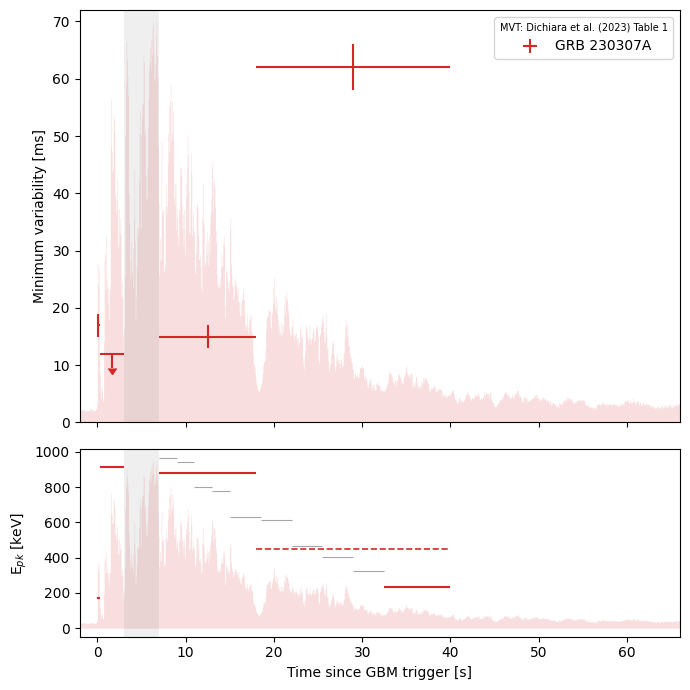

In [3]:
edges = aligned_bin_edges((-2.0, 66.0), 0.064)
centres = 0.5 * (edges[:-1] + edges[1:])
lc = sum(band_counts(DATA_DIR, BURST_ID, d, (8.0, 1000.0), edges) for d in SOFT_DETECTORS).astype(float)
lc /= lc.max()

def half(df):
    return 0.5 * (df.t_stop - df.t_start)

def mid(df):
    return 0.5 * (df.t_start + df.t_stop)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
top.fill_between(centres, 70 * lc, step="mid", color="tab:red", alpha=0.15, lw=0)
measured = merged[~merged.upper_limit.astype(bool)]
limits = merged[merged.upper_limit.astype(bool)]
top.errorbar(mid(measured), 1e3 * measured.mvt_s, xerr=half(measured),
             yerr=[1e3 * measured.mvt_err_lo_s, 1e3 * measured.mvt_err_hi_s], fmt="none", ecolor="tab:red", lw=1.5,
             label="GRB 230307A")
top.errorbar(mid(limits), 1e3 * limits.mvt_s, xerr=half(limits), yerr=2.5, uplims=True, fmt="none",
             ecolor="tab:red", color="tab:red", lw=1.5)
top.set_ylabel("Minimum variability [ms]")
top.set_ylim(0, 72)
top.legend(loc="upper right", title=f"MVT: {mvt_source}", title_fontsize=7)

shown = epeak.loc[["pre", "m01", "t1_07_18", "m11"]]           # the four E_peak points in Dichiara's Fig. 2
shown_err = np.hypot(0.5 * (shown.Epeak_err_lo + shown.Epeak_err_hi), shown.Epeak_sys)
others = epeak[~epeak.index.isin(shown.index) & (epeak.index != "t1_18_40")]
bottom.fill_between(centres, 950 * lc, step="mid", color="tab:red", alpha=0.15, lw=0)
bottom.errorbar(mid(others), others.Epeak_keV, xerr=half(others), fmt="none", ecolor="grey", lw=0.8, alpha=0.7)
bottom.errorbar(mid(shown), shown.Epeak_keV, xerr=half(shown), yerr=shown_err, fmt="none", ecolor="tab:red", lw=1.5)
long_window = epeak.loc["t1_18_40"]
bottom.hlines(long_window.Epeak_keV, long_window.t_start, long_window.t_stop, colors="tab:red", linestyles="--", lw=1.2)
bottom.set_ylabel("E$_{pk}$ [keV]")
bottom.set_xlabel("Time since GBM trigger [s]")
bottom.set_xlim(-2, 66)
for ax in (top, bottom):
    ax.axvspan(*BAD_TIME_INTERVAL, color="grey", alpha=0.12, lw=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "13_dichiara_fig2.png", dpi=200)
plt.show()

The E_peak points can be checked against the figure itself. Read off Dichiara's Fig. 2 (about 9 keV per pixel,
so +/-10-20 keV), their 7-18 s point is at ~870 keV; mine is 878 +/- 4 keV. Their precursor, 0.32-3 s and
32.5-40 s points sit at ~175, ~910 and ~225 keV, the Table 2 values.

## E_peak against MVT

Log-log, errors on both axes, the precursor marked separately, upper limits as arrows. The dark E_peak bars are statistical
and systematic. The pale bars add the instrument uncertainty from notebook 15 (GBM against GECAM): 10%, and 20% for the precursor.

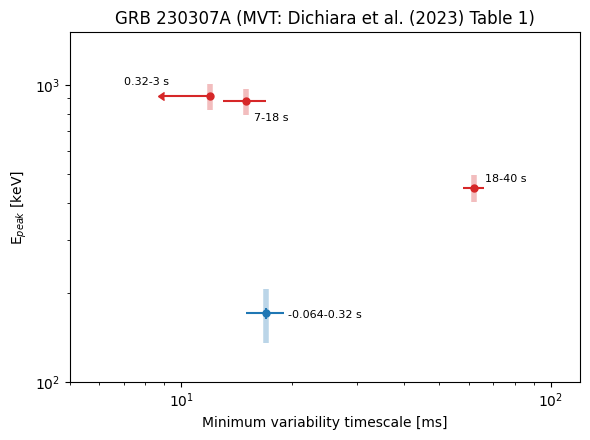

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for label, row in merged.iterrows():
    colour = "tab:blue" if label == "pre" else "tab:red"
    x, y = 1e3 * row.mvt_s, row.Epeak_keV
    ax.errorbar(x, y, yerr=np.hypot(row.Epeak_err, row.Epeak_instrument_keV), fmt="none", ecolor=colour, alpha=0.3, lw=4)
    if row.upper_limit:
        ax.errorbar(x, y, xerr=0.25 * x, yerr=row.Epeak_err, xuplims=True, fmt="o", color=colour, ms=5)
    else:
        ax.errorbar(x, y, xerr=[[1e3 * row.mvt_err_lo_s], [1e3 * row.mvt_err_hi_s]], yerr=row.Epeak_err,
                    fmt="o", color=colour, ms=5)
    offset = {"pre": (16, -3), "m01": (-62, 8), "t1_07_18": (6, -14), "t1_18_40": (8, 4)}.get(label, (6, 4))
    ax.annotate(f"{row.t_start:g}-{row.t_stop:g} s", (x, y), textcoords="offset points", xytext=offset, fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="Minimum variability timescale [ms]", ylabel="E$_{peak}$ [keV]",
       title=f"GRB 230307A (MVT: {mvt_source})")
ax.set_xlim(5, 120)
ax.set_ylim(100, 1500)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "13_epeak_vs_mvt.png", dpi=200)
plt.show()

With Dichiara's MVT, the main-emission windows follow the trend they describe: the shortest variability
(< 12 ms in 0.32-3 s, 15 ms in 7-18 s) goes with the hardest spectra (E_peak ~880-915 keV), and the slowest
variability (62 ms in 18-40 s) with a softer one (~450 keV). The precursor is the exception: variability as
short as the main emission (17 ms) with a much softer spectrum (170 keV). In the rest frame (z = 0.065) every
E_peak is 6.5% higher: 181 keV for the precursor, 973 and 935 keV for 0.32-3 s and 7-18 s, and 480 keV for
18-40 s. The contrast survives the instrument uncertainty: the pale bars of the precursor and the main emission don't
come close to overlapping. This is the comparison to redo with the new MVT values, window by window.

The merged table is saved next to the inputs, with the MVT source in it.

In [5]:
merged.assign(mvt_source=mvt_source).to_csv(SHARED / "epeak_mvt_230307A.csv", float_format="%.6g")
print("saved", SHARED / "epeak_mvt_230307A.csv")

saved /home/ignaciobl2004/mphys_project/ignacio/shared/epeak_mvt_230307A.csv
